# 02 · Experiment detail (RBP-ARK)

Every eCLIP experiment has its own page on RBP-ARK, with quality control (QC), a UCSC track hub and the file of windows. QKI has three experiments that pass QC: one from ENCORE2 in K562 cells and two from ENCODE3, in K562 and in HepG2 cells.

This notebook collects the same information in code and saves each experiment's windows near PICALM, which notebook 07 draws in the figure.

On Google Colab, run the next cell first in every session. It copies this repository onto the Colab machine and, with `SAVE_TO_DRIVE = True`, saves results and the figure to `My Drive/CS3_workflow` (Colab asks for permission to connect your Drive). `LITE = True` uses a small subset of the data that fits free Colab. On your own computer the cell does nothing.

In [ ]:
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess
    REPO = "https://github.com/yeolab/encode-rbp-case-study"
    CLONE = "/content/encode-rbp-case-study"
    LITE = True    # True: small subset of the data, fits free Colab (about 1 h). False: all the data (5-8 h, ~50 GB)
    SAVE_TO_DRIVE = True    # results and the figure in My Drive/CS3_workflow; False: on this Colab machine only
    if not os.path.isdir(CLONE):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, CLONE], check=True)
    WORKFLOW = CLONE + "/notebooks/workflow"
    OUTPUT = None
    if SAVE_TO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        OUTPUT = "/content/drive/MyDrive/CS3_workflow"
    sys.path.insert(0, WORKFLOW)
    import colab_setup
    colab_setup.setup(WORKFLOW, lite=LITE, output_folder=OUTPUT)

## In the browser

1. On the [Experiments](https://rbp-ark.com/search/?q=QKI) page, search for QKI. All three experiments pass QC.

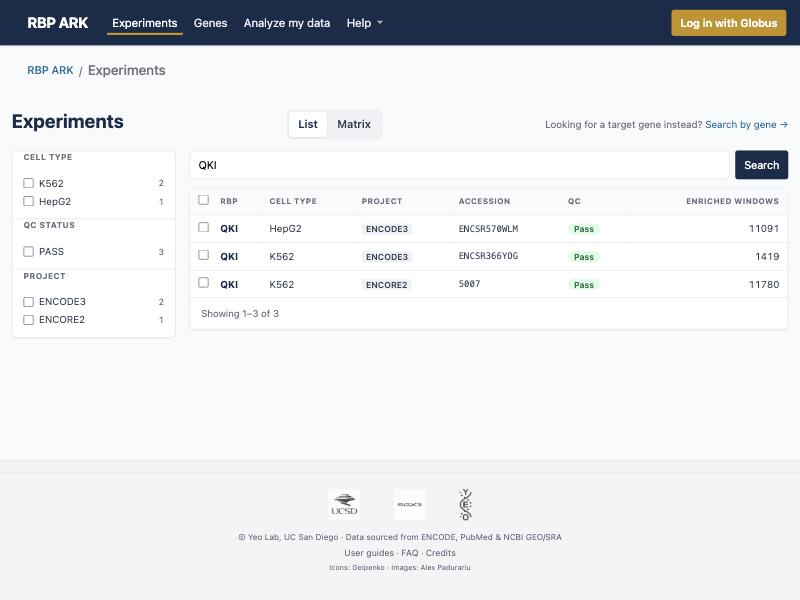

2. Open one, here the ENCORE2 experiment (accession 5007). The read table shows how many reads are left after trimming, mapping and removing PCR duplicates. The buttons at the top download a BDBag (notebook 03) or start a Globus transfer.

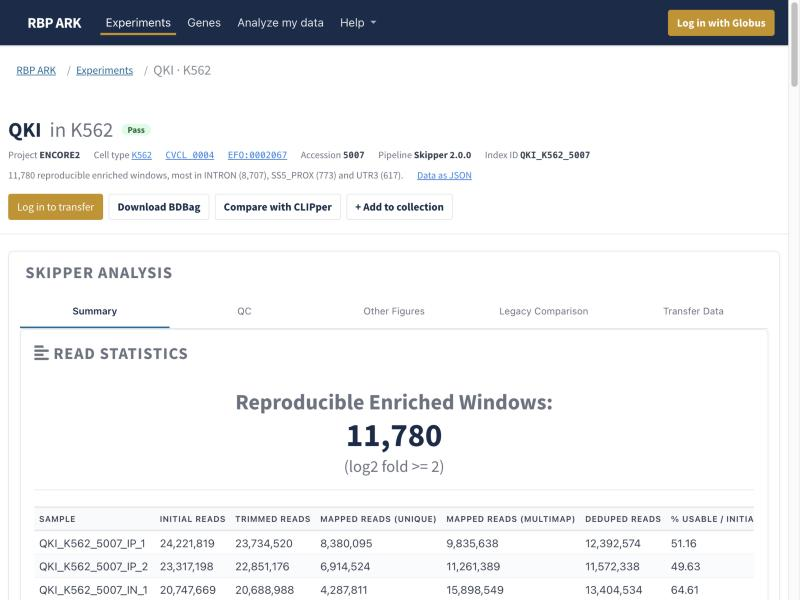

3. Further down are the track hub address and the windows file. To see the signal in the UCSC Genome Browser, paste the address into My Data > Track Hubs (or use the links the code below prints).

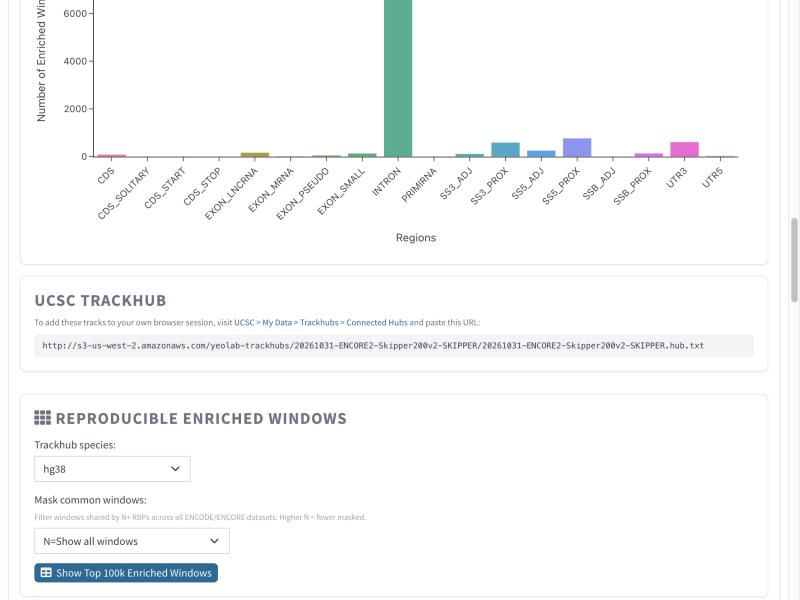

## In code

In [ ]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, ".")
import workflow_utils as U

ROOT, DATA = U.folders()
RESULTS = ROOT / "results" / "workflow"
API_CACHE = DATA / "downloads" / "rbpark_api"
print("case study folder:", ROOT)
print("data folder:", DATA)

In [ ]:
experiments = U.experiments_table(API_CACHE)
experiments[experiments["rbp"] == U.RBP]

Reads per sample, from the same QC summary the page shows. IP is the immunoprecipitated sample; IN is its size-matched input.

In [ ]:
stats = pd.concat({subject: U.read_stats(subject, API_CACHE) for subject in U.ECLIP}, names=["experiment"])
stats

In [ ]:
region = "{}:{}-{}".format(U.LOCUS[0], U.LOCUS[2], U.LOCUS[3])
for subject in U.ECLIP:
    hub = U.experiment_record(subject, API_CACHE, "trackhub_url")["trackhub_url"]
    link = f"https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&hubUrl={hub}&position={region}"
    display(Markdown(f"{subject}: [open the track hub at PICALM in UCSC]({link})"))

## Windows near PICALM

`reproducible_windows()` downloads an experiment's windows file (a few MB) once. `log2_enrichment` is the mean log2 fold over input and `q_value` the adjusted p-value; these are the numbers the gene search shows. The figure shades windows by enrichment and outlines those at log2 ≥ 3.

In [ ]:
parts = []
for subject in U.ECLIP:
    near = U.windows_in(U.reproducible_windows(subject, API_CACHE), *U.LOCUS)
    parts.append(near.assign(subject=subject)[["subject", "chr", "start", "end", "strand", "feature_type_top",
                                                "log2_enrichment", "q_value"]])
windows = pd.concat(parts, ignore_index=True)
for exon, info in U.EXONS.items():
    windows["nt from " + info["name"]] = [U.relative_position(s, e, exon) for s, e in zip(windows["start"], windows["end"])]
windows.to_csv(RESULTS / "02_qki_windows_PICALM.tsv", sep="\t", index=False)
print(len(windows), "QKI windows between", U.LOCUS[2], "and", U.LOCUS[3])
windows[windows[["nt from 150-nt exon", "nt from 24-nt exon"]].abs().min(axis=1) <= 100]

Expected: the window before the 150-nt exon has log2 enrichment 4.08 (ENCORE2), 3.31 (ENCODE3 K562) and 2.40 (HepG2); the window after the 24-nt exon has 4.59, 3.40 and 4.28.